<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Logistic Regression Implementation with Diagnostic Visualizations
This notebook demonstrates a complete, end-to-end implementation of the **Logistic Regression** classifier using standard data science libraries (`scikit-learn`, `matplotlib`, and `seaborn`).

### Workflow Overview:
1. **Data Generation**: Create a synthetic 2D binary classification dataset.
2. **Preprocessing**: Split the dataset into training and test splits.
3. **Model Training**: Fit a Logistic Regression model to the training data.
4. **Evaluation**: Compute standard classification metrics (Accuracy, Precision, Recall, F1-Score).
5. **Visualization**: Plot the decision boundary and the Confusion Matrix.
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate a synthetic 2D binary classification dataset
X, y = make_classification(
    n_samples=300,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=1.5,
    random_state=42
)

# 2. Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Instantiate and train the Logistic Regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# 4. Predict on the test set
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# 5. Compute performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

# --- Presentable Console Output ---
print("="*45)
print("       LOGISTIC REGRESSION PERFORMANCE       ")
print("="*45)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print("="*45)

       LOGISTIC REGRESSION PERFORMANCE       
Accuracy  : 0.9833
Precision : 0.9688
Recall    : 1.0000
F1-Score  : 0.9841


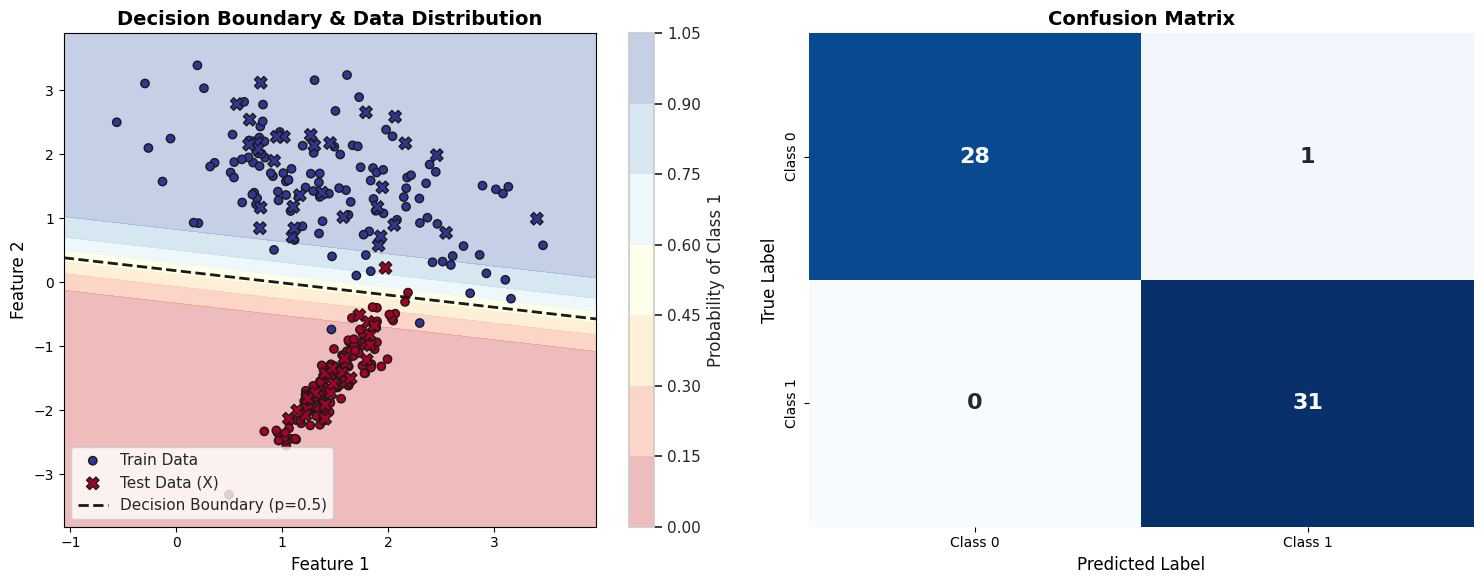

In [2]:
# Setup the visualization canvas
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.set_theme(style="whitegrid")

# --- Plot 1: Decision Boundary ---
ax1 = axes[0]

# Create a mesh grid for background coloring
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# Predict probabilities over the grid
Z = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
Z = Z.reshape(xx.shape)

# Plot background probability contour
contour = ax1.contourf(xx, yy, Z, alpha=0.3, cmap='RdYlBu')
fig.colorbar(contour, ax=ax1, label='Probability of Class 1')

# Plot training points
scatter = ax1.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='RdYlBu', edgecolors='k', label='Train Data')
# Plot testing points with a distinct marker shape
ax1.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='RdYlBu', marker='X', s=80, edgecolors='k', label='Test Data (X)')

# Extract decision boundary line (P=0.5)
b_coef = model.coef_[0]
b_intercept = model.intercept_[0]
x_vals = np.array([x_min, x_max])
y_vals = -(b_coef[0] * x_vals + b_intercept) / b_coef[1]
ax1.plot(x_vals, y_vals, '--k', linewidth=2, label='Decision Boundary (p=0.5)')

ax1.set_title("Decision Boundary & Data Distribution", fontsize=14, fontweight='bold')
ax1.set_xlabel("Feature 1", fontsize=12)
ax1.set_ylabel("Feature 2", fontsize=12)
ax1.legend(loc='lower left')
ax1.set_xlim(x_min, x_max)
ax1.set_ylim(y_min, y_max)

# --- Plot 2: Confusion Matrix ---
ax2 = axes[1]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2,
            annot_kws={'size': 16, 'weight': 'bold'},
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])

ax2.set_title("Confusion Matrix", fontsize=14, fontweight='bold')
ax2.set_xlabel("Predicted Label", fontsize=12)
ax2.set_ylabel("True Label", fontsize=12)

plt.tight_layout()
plt.show()